# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    board = np.array(board)

    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")

    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]

        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")

    return(val)

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea:

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    cnt = [0] * (5 * n)

    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1

    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)

    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

In [6]:
import timeit

# run it once to force compilation
conflicts_jit(random_board(4))

reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []


for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]

    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )


    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')


Times for 8x8 board in microseconds
naive: 111.31044999928008, linear: 13.166649999618585, jit: 1.0531499995636295


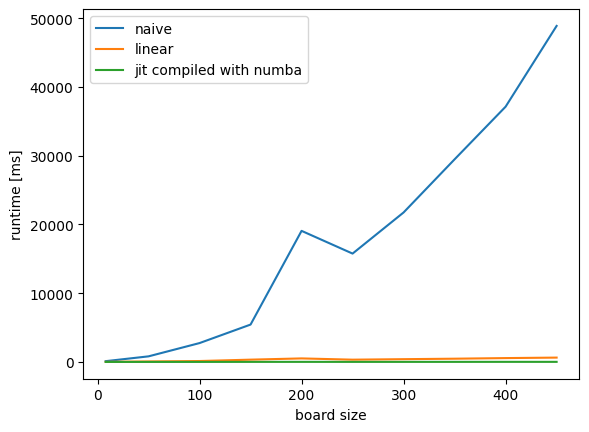

In [7]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

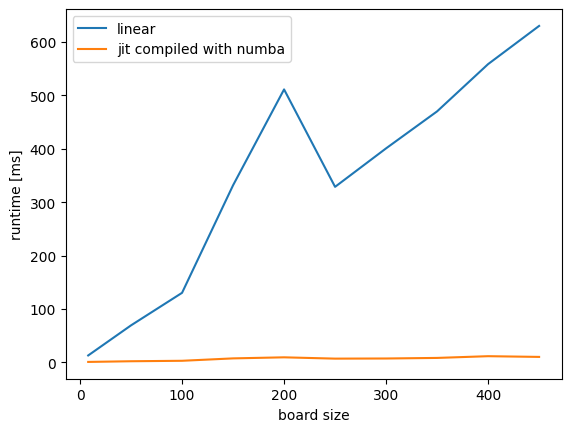

In [8]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

Nhận xét:

Qua quá trình thực nghiệm tính số xung đột trong bài toán N-Queens, có thể thấy việc tối ưu hóa hàm mục tiêu giúp cải thiện đáng kể hiệu suất thực thi.

Phương pháp Naive sử dụng các vòng lặp lồng nhau để kiểm tra xung đột giữa các quân hậu, có độ phức tạp thời gian (O(n^2)). Do đó, thời gian thực thi tăng nhanh khi kích thước bàn cờ tăng.

Phương pháp Linear cải thiện hiệu suất bằng cách đếm số quân hậu trong từng hàng và từng đường chéo, sau đó tính số cặp xung đột bằng công thức (k(k-1)/2). Với cách tổ chức này, độ phức tạp thời gian giảm xuống (O(n)), giúp giảm đáng kể chi phí tính toán so với phương pháp Naive.

Phương pháp Numba JIT tiếp tục tối ưu thời gian thực thi bằng cách biên dịch hàm tính xung đột trước khi tiến hành đo hiệu suất. Trong kết quả thử nghiệm, phiên bản JIT có thời gian tính toán thấp nhất trong ba phương pháp. Tuy nhiên, thời gian biên dịch ban đầu chưa được tính vào kết quả đo, vì vậy lợi thế này thể hiện rõ hơn khi hàm được gọi lặp lại nhiều lần.

Kết quả kiểm tra trên các bàn cờ ngẫu nhiên cho thấy cả ba phương pháp trả về cùng số xung đột trong các trường hợp đã thử. Điều này cho thấy việc tối ưu hóa không làm thay đổi kết quả tính toán trong phạm vi kiểm thử.

Tóm lại, phương pháp Linear giúp giảm độ phức tạp thuật toán, trong khi Numba JIT tiếp tục giảm chi phí thực thi thực tế. Đây là cải tiến có ý nghĩa đối với các thuật toán tìm kiếm cục bộ như Hill Climbing và Simulated Annealing, vì hàm mục tiêu cần được tính toán nhiều lần trong quá trình tìm nghiệm. Các kết quả thời gian vẫn phụ thuộc vào môi trường chạy và cần được đánh giá bằng nhiều lần thử để tăng độ tin cậy.